# Практическое занятие №2. Обучение нейронных сетей

## Полносвязная нейронная сеть (MLP) на датасете Palmer Penguins

**Дисциплина:** Методы машинного обучения
**Кафедра:** Интеллектуальных информационных систем и кибербезопасности
**ВУЗ:** АНО ВО РОСНОУ
**Преподаватель:** Марков Артем Алексеевич
**Студент:** Галимский Дмитрий, группа 413м

---

## Постановка задачи

Требуется обучить полносвязную нейронную сеть и решить на ней задачу
**многоклассовой классификации**: по четырём анатомическим признакам птицы
определить её вид.

Архитектура MLP по определению работает с одномерными векторами признаков
и табличными данными - именно такой тип данных используется в работе.

По методичке работа разбита на четыре части, и ниже они идут именно
в таком порядке:

1. **Данные** - выбор датасета, разведка, приведение к машинному виду.
2. **Архитектура** - проектирование слоёв сети под тип данных.
3. **Обучение** - реализация цикла обучения.
4. **Оценка** - метрики качества и разбор ошибок.

После оценки - выводы, где разбирается, что получилось и почему.


In [1]:
# Ячейка 1 - зависимости.
#
# В Google Colab этот стек уже установлен, и команда ничего не скачивает.
# Локально она ставит недостающее, поэтому один и тот же ноутбук работает
# и в облаке, и на машине. Версии не фиксируем: pip подберёт совместимые.
%pip install -q torch torchvision numpy pandas scikit-learn matplotlib seaborn

# Проверяем, что всё действительно доступно, - иначе ошибка всплывёт
# не в этой ячейке, а где-нибудь в середине обучения.
import importlib

for _package in ("torch", "torchvision", "numpy", "pandas", "sklearn",
                 "matplotlib", "seaborn"):
    _module = importlib.import_module(_package)
    print(f"{_package:12s} {_module.__version__}")


Note: you may need to restart the kernel to use updated packages.


torch        2.14.0+cpu


torchvision  0.29.1+cpu
numpy        2.5.3


pandas       3.0.5


sklearn      1.9.1


matplotlib   3.11.2


seaborn      0.13.2


In [2]:
# Все импорты собраны в одной ячейке в самом верху файла - так их удобнее
# просматривать, и ниже по ноутбуку не остаётся «внезапно» появляющихся
# библиотек.

# Ядро вычислений. torch - сам фреймворк, nn - готовые слои нейросети,
# torch.nn.functional - функции активации и потерь без создания лишних объектов.
import torch
from torch import nn
import torch.nn.functional as F

# Загрузка и перемешивание батчей во время обучения.
from torch.utils.data import DataLoader, TensorDataset

# Оптимизатор и планировщик скорости обучения (понижаем lr, когда метрика
# перестала улучшаться - это спасает от застревания на плато).
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Работа с табличными данными: чтение CSV, пропуски, группировка.
import pandas as pd

# Численные операции и перестановка/перемешивание индексов.
import numpy as np

# Графики. pyplot - базовые графики, seaborn - аккуратные heatmap и boxplot.
import matplotlib.pyplot as plt
import seaborn as sns

# Метрики качества и матрица ошибок.
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

# Наивные классификаторы как базовая линия для сравнения.
from sklearn.dummy import DummyClassifier

# Разделение выборок: обучающая, валидационная и тестовая строятся одним вызовом,
# с сохранением исходных индексов строк - они понадобятся в разборе ошибок.
from sklearn.model_selection import train_test_split

# Стандартизация: переводит признаки к нулевому среднему и единичному разбросу,
# иначе масштаб признаков разный и градиенты по одним будут в тысячи раз больше.
from sklearn.preprocessing import StandardScaler

# Снижение размерности: нужна, чтобы посмотреть, как признаки ложатся
# на плоскость и не разбросаны ли два класса одинаково.
from sklearn.decomposition import PCA

In [3]:
# Воспроизводимость: фиксируем генератор случайных чисел PyTorch,
# иначе каждый запуск ноутбука давал бы немного разные веса и метрики.
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Устройство: на ноутбуке без видеокарты считаем на CPU,
# в Google Colab с включённым GPU - автоматически на CUDA.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch версии {torch.__version__}, устройство: {device}")

# Единый стиль оформления всех графиков ноутбука.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)

PyTorch версии 2.14.0+cpu, устройство: cpu


## 1. Описание датасета

**Palmer Penguins** (Палмеровские пингвины) - открытый набор данных, собранный
на антарктической станции Палмер в 2008-2010 годах. В нём 344 наблюдения
и 7 столбцов.

| Столбец | Тип | Что означает |
|---|---|---|
| `species` | категориальный | **Целевая переменная**: вид птицы - Adelie, Chinstrap, Gentoo |
| `island` | категориальный | Остров обитания: Torgersen, Biscoe, Dream |
| `bill_length_mm` | числовой | Длина клюва в миллиметрах |
| `bill_depth_mm` | числовой | Толщина (глубина) клюва в миллиметрах |
| `flipper_length_mm` | числовой | Длина ласта в миллиметрах |
| `body_mass_g` | числовой | Масса тела в граммах |
| `sex` | категориальный | Пол: Male, Female |

Датасет выбран потому, что он:

* содержит **пропуски** - их нужно обработать до обучения;
* смешивает **числовые и категориальные** признаки - требуется кодирование;
* имеет **сильно разные масштабы** (масса в граммах, длина ласта в миллиметрах),
  что наглядно показывает, зачем нейросети нормализация;
* не использовался в практике №1.

In [4]:
# Датасет лежит в открытом репозитории seaborn и читается обычным read_csv.
PENGUINS_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
df = pd.read_csv(PENGUINS_URL)

print(f"Размер таблицы: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

Размер таблицы: 344 строк, 7 столбцов


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


## 2. Разведочный анализ данных

### 2.1 Пропуски

,пропусков,доля_строк
bill_length_mm,2,0.006
bill_depth_mm,2,0.006
flipper_length_mm,2,0.006
body_mass_g,2,0.006
sex,11,0.032


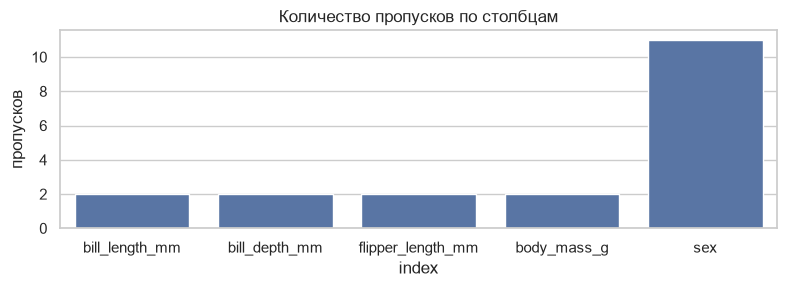

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].rename("пропусков").to_frame()
missing["доля_строк"] = (missing["пропусков"] / len(df)).round(3)
display(missing)

fig, ax = plt.subplots(figsize=(8, 3))
sns.barplot(data=missing.reset_index(), x="index", y="пропусков", ax=ax, color="#4C72B0")
ax.set_title("Количество пропусков по столбцам")
plt.tight_layout()
plt.show()

### 2.2 Дубликаты

In [6]:
duplicates = df.duplicated().sum()
print(f"Полностью повторяющихся строк: {duplicates}")
print("Вывод: дубликатов нет, удалять нечего." if duplicates == 0
      else f"Вывод: найдено {duplicates} повторов, они удаляются ниже.")

Полностью повторяющихся строк: 0
Вывод: дубликатов нет, удалять нечего.


### 2.3 Распределение целевой переменной

,объектов
species,
Adelie,152
Gentoo,124
Chinstrap,68


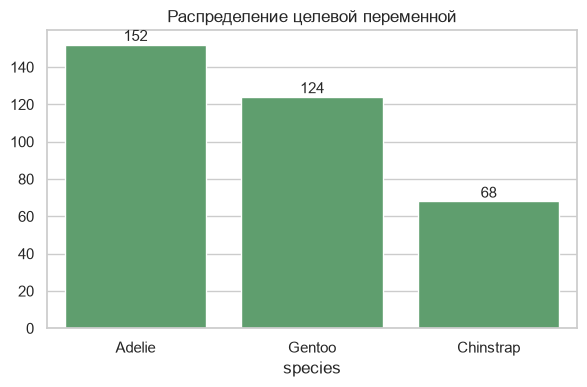

In [7]:
counts = df["species"].value_counts()
display(counts.rename("объектов").to_frame())

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#55A868")
ax.set_title("Распределение целевой переменной")
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, str(v), ha="center")
plt.tight_layout()
plt.show()

### 2.4 Распределения числовых признаков

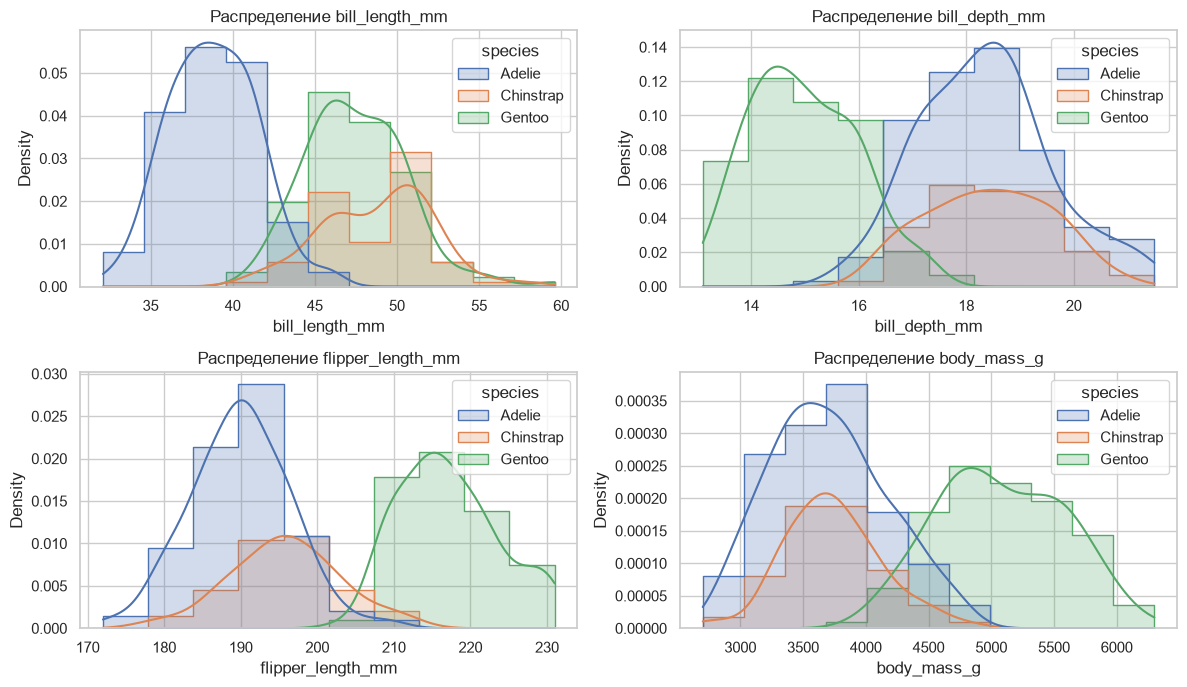

In [8]:
numeric_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, column in zip(axes.flat, numeric_features):
    sns.histplot(data=df, x=column, hue="species", kde=True, ax=ax, element="step", stat="density")
    ax.set_title(f"Распределение {column}")
plt.tight_layout()
plt.show()

C:\Users\Druli\AppData\Local\Temp\ipykernel_16464\1369721310.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y=column, ax=ax, palette="Set2")
C:\Users\Druli\AppData\Local\Temp\ipykernel_16464\1369721310.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y=column, ax=ax, palette="Set2")


C:\Users\Druli\AppData\Local\Temp\ipykernel_16464\1369721310.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y=column, ax=ax, palette="Set2")
C:\Users\Druli\AppData\Local\Temp\ipykernel_16464\1369721310.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y=column, ax=ax, palette="Set2")


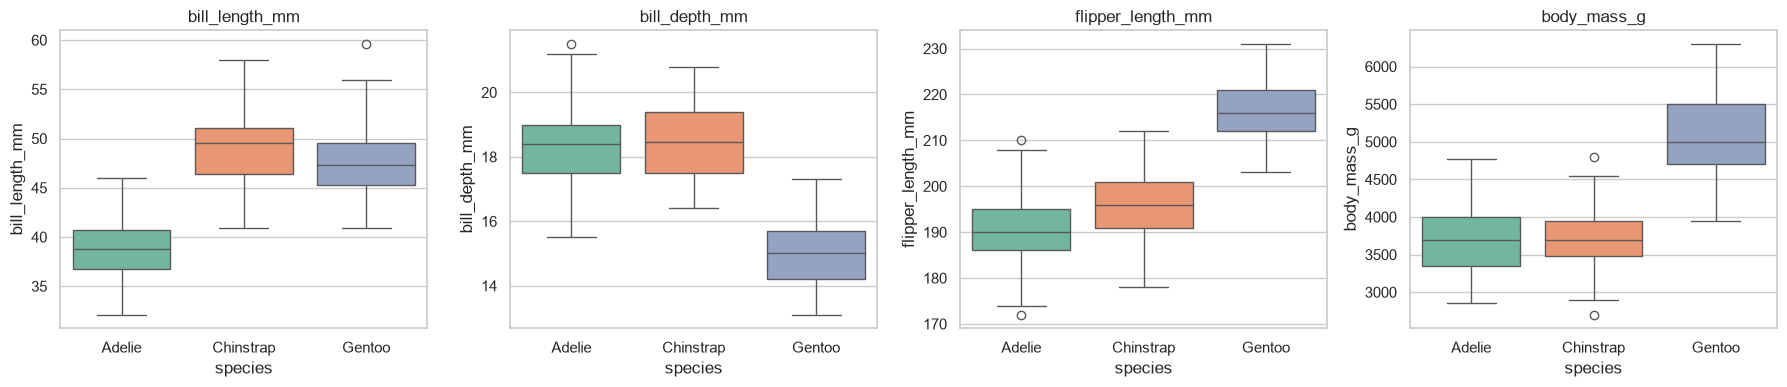

In [9]:
# Видно, что виды заметно различаются по длине ласта и массе тела,
# а вот длина клюва распределена почти одинаково - признак слабый.
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, column in zip(axes, numeric_features):
    sns.boxplot(data=df, x="species", y=column, ax=ax, palette="Set2")
    ax.set_title(column)
plt.tight_layout()
plt.show()

### 2.5 Матрица корреляции

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.00,-0.24,0.66,0.60
bill_depth_mm,-0.24,1.00,-0.58,-0.47
flipper_length_mm,0.66,-0.58,1.00,0.87
body_mass_g,0.60,-0.47,0.87,1.00


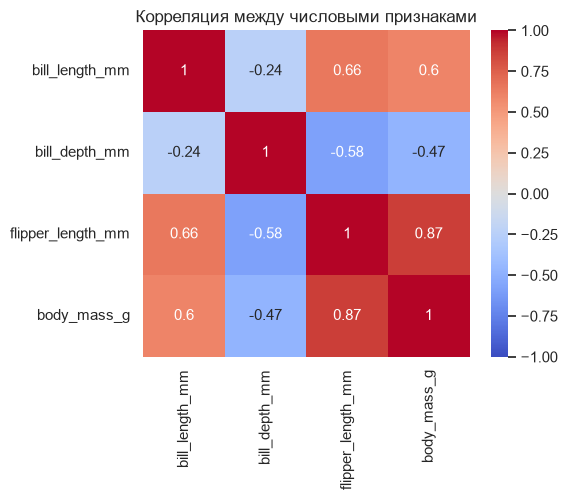

In [10]:
correlation = df[numeric_features].corr()
display(correlation.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Корреляция между числовыми признаками")
plt.tight_layout()
plt.show()

**Вывод по разделу.** Данные приемлемого качества: полных дубликатов нет,
пропусков меньше 6% (точное число - в выводе ячейки выше), но классы
распределены неравномерно - поэтому метрику
accuracy будем считать **вместе с macro-F1**, который штрафует модель за плохую
работу с редким классом.

---

## 3. Подготовка данных

Порядок обработки важен: сначала пропуски, потом кодирование,
и только в самом конце - масштабирование.

In [11]:
# Шаг 1. Целевая переменная - единственное поле, которое нельзя заполнять:
# строки без вида птицы не несут информации и просто удаляются.
df = df.dropna(subset=["species"]).copy()

# Шаг 2. Числовые пропуски заполняем медианой - она устойчива к выбросам,
# в отличие от среднего.
numeric_features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
df[numeric_features] = df[numeric_features].fillna(df[numeric_features].median())

# Шаг 3. Категориальные пропуски заполняем модой (самым частым значением).
for column in ["island", "sex"]:
    df[column] = df[column].fillna(df[column].mode()[0])

# Проверяем, что пропусков больше не осталось.
print("Осталось пропусков:", int(df.isna().sum().sum()))
print("Строк после удаления:", len(df))
display(df.head())

Осталось пропусков: 0
Строк после удаления: 344


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.10,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.50,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.30,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,44.45,17.3,197.0,4050.0,MALE
4,Adelie,Torgersen,36.70,19.3,193.0,3450.0,FEMALE


In [12]:
# Шаг 4. Кодируем категориальные признаки методом One-Hot:
# каждый остров и пол превращаются в отдельный столбец из нулей и единиц.
# drop_first=True убирает избыточный столбец-«пустышка», чтобы не было
# мультиколлинеарности (линейной зависимости между признаками).
df_encoded = pd.get_dummies(
    df,
    columns=["island", "sex"],
    drop_first=True,
    dtype=float,
)

# Шаг 5. Целевая переменная переводим из строк в числа по индексам классов.
species_classes = sorted(df["species"].unique())
class_to_index = {name: index for index, name in enumerate(species_classes)}
df_encoded["target"] = df["species"].map(class_to_index)

print("Классы и их коды:", class_to_index)
print("Итоговый набор признаков:")
display(df_encoded.head())
print("Число признаков после кодирования:", df_encoded.shape[1] - 1)

Классы и их коды: {'Adelie': 0, 'Chinstrap': 1, 'Gentoo': 2}
Итоговый набор признаков:


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE,target
0,Adelie,39.10,18.7,181.0,3750.0,0.0,1.0,1.0,0
1,Adelie,39.50,17.4,186.0,3800.0,0.0,1.0,0.0,0
2,Adelie,40.30,18.0,195.0,3250.0,0.0,1.0,0.0,0
3,Adelie,44.45,17.3,197.0,4050.0,0.0,1.0,1.0,0
4,Adelie,36.70,19.3,193.0,3450.0,0.0,1.0,0.0,0


Число признаков после кодирования: 8


### 3.1 Разделение на обучающую, валидационную и тестовую выборки

Выборок три, и это важно:

* **обучающая** - на ней подбираются веса сети;
* **валидационная** - на ней принимаются решения о ходе обучения
  (какой эпохой остановиться, когда понизить скорость обучения);
* **тестовая** - только один раз, в самом конце, для честной оценки.

Если выбирать «лучшую эпоху» по тестовой выборке, то тест перестаёт быть
проверкой: модель фактически подстраивается под него, и оценка получается
завышенной. Поэтому в этой работе ни тест, ни валидация не участвуют
в подборе гиперпараметров - сеть обучается с фиксированными настройками,
а валидация нужна только для остановки.

In [13]:
# Целевая переменная переводится в числовой код, а столбец species убираем -
# иначе в матрицу признаков попадёт текст, и её нельзя будет превратить в float.
X = df_encoded.drop(columns=["target", "species"]).to_numpy(dtype=np.float32)
y = df_encoded["target"].to_numpy(dtype=np.int64)
all_index = df_encoded.index.to_numpy()

# Первый шаг: отделяем 20% данных под финальную проверку.
X_temp, X_test, y_temp, y_test, temp_index, test_index = train_test_split(
    X, y, all_index, test_size=0.2, random_state=SEED, stratify=y
)

# Второй шаг: из оставшихся 80% отделяем 25% под валидацию.
# Итого получается 60% на обучение, 20% на валидацию и 20% на тест.
X_train, X_val, y_train, y_val, train_index, val_index = train_test_split(
    X_temp, y_temp, temp_index, test_size=0.25, random_state=SEED, stratify=y_temp
)

print(f"Обучающая выборка:  {X_train.shape}")
print(f"Валидационная:      {X_val.shape}")
print(f"Тестовая:           {X_test.shape}")
print("Итоговое число признаков:", X.shape[1])
for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"  {name:5s}: {np.bincount(labels, minlength=3)}")

Обучающая выборка:  (206, 7)
Валидационная:      (69, 7)
Тестовая:           (69, 7)
Итоговое число признаков: 7
  train: [91 41 74]
  val  : [31 13 25]
  test : [30 14 25]


### 3.2 Масштабирование признаков

Нейронная сеть обучается градиентным спуском. Если один признак измеряется
в граммах (масса ~5000), а другой - в долях единицы, то градиенты по первому
признаку окажутся в тысячи раз больше, и сеть будет «метаться» вместо
обучения. Поэтому все признаки приводят к нулевому среднему и единичному
разбросу.

**Важно:** параметры масштабирования находят только на обучающей выборке,
остальные выборки только преобразуют - иначе модель «подсмотрела бы» в ответы.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Средние после масштабирования (должны быть ~0):", np.round(X_train_scaled.mean(axis=0), 6))
print("Стандартные отклонения (должны быть ~1):", np.round(X_train_scaled.std(axis=0), 3))

Средние после масштабирования (должны быть ~0):

 [-0.  0.  0. -0. -0.  0.  0.]
Стандартные отклонения (должны быть ~1): [1. 1. 1. 1. 1. 1. 1.]


---

## 4. Архитектура нейронной сети

Слои подобраны под тип данных: во входных данных 7 числовых признаков
(4 анатомических + 2 острова + 1 пол, вторые категории кодирования убираются),
на выходе - 3 класса.

```
вход  7  - 4 анатомических + 2 острова (из 3) + 1 пол (из 2)
  ↓ BatchNorm1d(7)
  ↓ Linear 7 → 128 + ReLU
  ↓ Dropout 0.3
  ↓ Linear 128 → 64 + ReLU
  ↓ Dropout 0.2
выход 3   - логиты для трёх видов пингвинов
```

Почему именно так:

* `BatchNorm1d` - стабилизирует распределение входов после каждого батча
  и ускоряет сходимость;
* два скрытых слоя - первый находит грубые комбинации признаков,
  второй их уточняет;
* `Dropout` - гасит часть нейронов при каждом проходе, защищая от переобучения;
* функция активации **ReLU** нужна, чтобы сеть была нелинейной: без неё
  любая глубина сводилась бы к одной линейной прямой.

In [15]:
class PenguinMLP(nn.Module):
    """Полносвязная нейронная сеть для классификации видов пингвинов."""

    def __init__(self, input_size: int, hidden_size1: int = 128, hidden_size2: int = 64,
                 num_classes: int = 3, dropout1: float = 0.3, dropout2: float = 0.2):
        super().__init__()
        self.batch_norm = nn.BatchNorm1d(input_size)
        self.layer1 = nn.Linear(input_size, hidden_size1)
        self.dropout1 = nn.Dropout(dropout1)
        self.layer2 = nn.Linear(hidden_size1, hidden_size2)
        self.dropout2 = nn.Dropout(dropout2)
        self.layer3 = nn.Linear(hidden_size2, num_classes)

    def forward(self, x):
        x = self.batch_norm(x)
        x = F.relu(self.layer1(x))
        x = self.dropout1(x)
        x = F.relu(self.layer2(x))
        x = self.dropout2(x)
        return self.layer3(x)


model = PenguinMLP(input_size=X_train_scaled.shape[1]).to(device)
print(model)

PenguinMLP(
  (batch_norm): BatchNorm1d(7, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layer1): Linear(in_features=7, out_features=128, bias=True)
  (dropout1): Dropout(p=0.3, inplace=False)
  (layer2): Linear(in_features=128, out_features=64, bias=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (layer3): Linear(in_features=64, out_features=3, bias=True)
)


In [16]:
# Считаем, сколько чисел обучается - полезно, чтобы понимать размер модели.
total_parameters = sum(p.numel() for p in model.parameters())
print(f"Всего обучаемых параметров: {total_parameters:,}")
for name, layer in model.named_children():
    print(f"  {name:10s} -> {layer}")

Всего обучаемых параметров: 9,489
  batch_norm -> BatchNorm1d(7, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  layer1     -> Linear(in_features=7, out_features=128, bias=True)
  dropout1   -> Dropout(p=0.3, inplace=False)
  layer2     -> Linear(in_features=128, out_features=64, bias=True)
  dropout2   -> Dropout(p=0.2, inplace=False)
  layer3     -> Linear(in_features=64, out_features=3, bias=True)


---

## 5. Обучение

Настройки обучения фиксированы и подбирались вручную: их подбор по тестовой
выборке сделал бы оценку завышенной, поэтому в работе обучение идёт вслепую,
а валидация служит только для остановки.

| Параметр | Значение |
|---|---|
| Оптимизатор | Adam, learning rate 0.001 |
| Планировщик | ReduceLROnPlateau, понижение lr вдвое при отсутствии роста |
| Размер батча | 32 |
| Эпох | не больше 150, досрочная остановка |
| Функция потерь | CrossEntropyLoss |

In [17]:
BATCH_SIZE = 32

train_dataset = TensorDataset(
    torch.from_numpy(X_train_scaled),
    torch.from_numpy(y_train).long(),
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          drop_last=True, generator=torch.Generator().manual_seed(SEED))

criterion = nn.CrossEntropyLoss()   # функция потерь для многоклассовой задачи
optimizer = Adam(model.parameters(), lr=1e-3)
scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=7)

print(f"Батчей на эпоху: {len(train_loader)}")

Батчей на эпоху: 6

In [18]:
def train_one_epoch(network, loader, loss_function, optimizer):
    """Один проход по обучающей выборке. Возвращает средние потери и точность."""
    network.train()                       # включает dropout и обновление BatchNorm
    total_loss = 0.0
    correct = 0
    seen = 0

    for batch_x, batch_y in loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        optimizer.zero_grad()              # обнуляем градиенты прошлого шага
        logits = network(batch_x)          # прямой проход
        loss = loss_function(logits, batch_y)
        loss.backward()                    # обратное распространение
        optimizer.step()                   # обновление весов

        total_loss += loss.item() * batch_y.size(0)
        correct += (logits.argmax(dim=1) == batch_y).sum().item()
        seen += batch_y.size(0)

    return total_loss / seen, correct / seen


@torch.no_grad()
def evaluate(network, x_array, y_array):
    """Прогон по выборке без градиентов - режим проверки, dropout выключен."""
    network.eval()
    logits = network(torch.from_numpy(x_array).to(device))
    predictions = logits.argmax(dim=1).cpu().numpy()
    accuracy = accuracy_score(y_array, predictions)
    return accuracy, predictions


print("Функции обучения и проверки готовы.")

Функции обучения и проверки готовы.


In [19]:
EPOCHS = 150

history = {"loss": [], "train_acc": [], "val_acc": []}
best_val_accuracy = 0.0
best_state = None
best_epoch = 0
epochs_without_progress = 0

for epoch in range(1, EPOCHS + 1):
    epoch_loss, epoch_train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    epoch_val_acc, _ = evaluate(model, X_val_scaled, y_val)

    history["loss"].append(epoch_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_acc"].append(epoch_val_acc)

    # Лучшие веса ищем по валидации, а не по тесту - иначе тестовая выборка
    # перестанет быть независимой проверкой.
    if epoch_val_acc > best_val_accuracy:
        best_val_accuracy = epoch_val_acc
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        best_epoch = epoch
        epochs_without_progress = 0
    else:
        epochs_without_progress += 1

    scheduler.step(epoch_val_acc)

    # Если точность на валидации 15 эпох не растёт - обучение остановлено:
    # дальше сеть будет только запоминать обучающую выборку.
    if epochs_without_progress == 15:
        print(f"\nВалидация не растёт 15 эпох - останавливаемся досрочно на эпохе {epoch}.")
        break

    if epoch % 10 == 0 or epoch == 1:
        print(f"Эпоха {epoch:3d} | потери {epoch_loss:.4f} | train {epoch_train_acc:.4f} | val {epoch_val_acc:.4f}")

# Возвращаем в модель те веса, которые показали лучший результат на валидации.
model.load_state_dict(best_state)
print(f"\nЛучшая точность на валидации: {best_val_accuracy:.4f} на эпохе {best_epoch}")
print(f"Обучено эпох: {len(history['loss'])}")

Эпоха   1 | потери 1.0658 | train 0.3490 | val 0.8406


Эпоха  10 | потери 0.1209 | train 0.9792 | val 0.9710


Эпоха  20 | потери 0.0278 | train 0.9948 | val 1.0000



Валидация не растёт 15 эпох - останавливаемся досрочно на эпохе 28.

Лучшая точность на валидации: 1.0000 на эпохе 13
Обучено эпох: 28


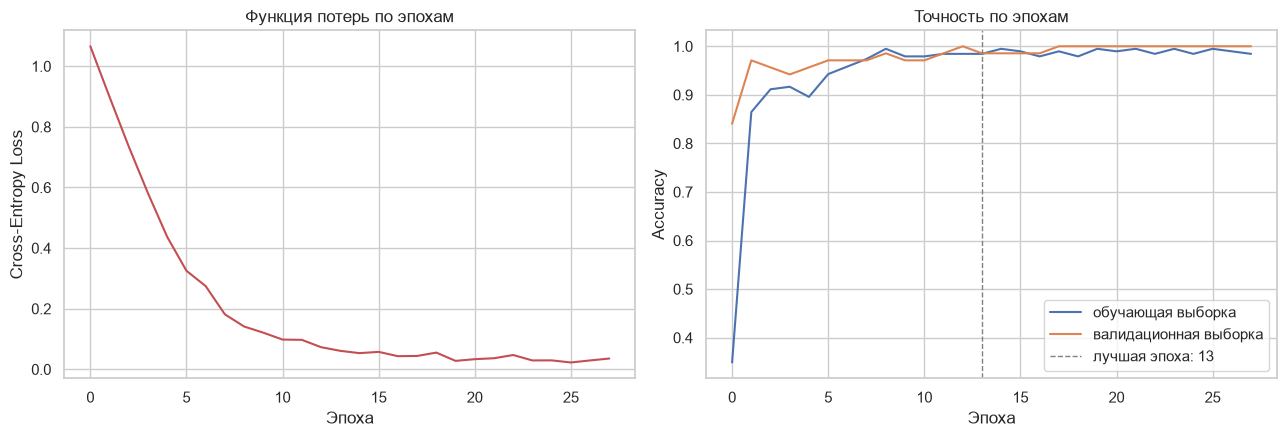

Разрыв train/val в конце обучения: -0.0156


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(history["loss"], color="#C44E52")
axes[0].set_title("Функция потерь по эпохам")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Cross-Entropy Loss")

axes[1].plot(history["train_acc"], label="обучающая выборка", color="#4C72B0")
axes[1].plot(history["val_acc"], label="валидационная выборка", color="#DD8452")
axes[1].axvline(best_epoch, color="gray", linestyle="--", linewidth=1,
                label=f"лучшая эпоха: {best_epoch}")
axes[1].set_title("Точность по эпохам")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

# Разрыв между этими двумя кривыми и есть цена переобучения.
final_gap = history["train_acc"][-1] - history["val_acc"][-1]
print(f"Разрыв train/val в конце обучения: {final_gap:.4f}")

---

## 6. Оценка результата

Модель выбрана по валидационной выборке, поэтому тестовая выборка впервые
используется здесь и даёт честную оценку.

### 6.1 Основные метрики

In [21]:
final_accuracy, predictions = evaluate(model, X_test_scaled, y_test)
f1_macro = f1_score(y_test, predictions, average="macro")
f1_weighted = f1_score(y_test, predictions, average="weighted")

print(f"Accuracy (тестовая выборка): {final_accuracy:.4f}")
print(f"Macro F1-score:             {f1_macro:.4f}")
print(f"Weighted F1-score:          {f1_weighted:.4f}")

# С кем сравнивать. Dummy-классификатор ничего не обучает, поэтому его точность -
# это честная нижняя граница, ниже которой результат бессмыслен.
dummy_most = DummyClassifier(strategy="most_frequent")
dummy_most.fit(X_train_scaled, y_train)
most_frequent_accuracy = dummy_most.score(X_test_scaled, y_test)

dummy_prior = DummyClassifier(strategy="prior")
dummy_prior.fit(X_train_scaled, y_train)
prior_accuracy = dummy_prior.score(X_test_scaled, y_test)

dummy_uniform = DummyClassifier(strategy="uniform", random_state=SEED)
dummy_uniform.fit(X_train_scaled, y_train)
uniform_accuracy = dummy_uniform.score(X_test_scaled, y_test)

print(f"\nБазовая линия - всегда самый частый класс: {most_frequent_accuracy:.4f}")
print(f"Базовая линия - случайная пропорция классов: {prior_accuracy:.4f}")
print(f"Базовая линия - равномерное случайное угадывание: {uniform_accuracy:.4f}")
print(f"\nВо сколько раз модель лучше главной базовой линии: "
      f"{final_accuracy / most_frequent_accuracy:.1f}")

Accuracy (тестовая выборка): 0.9855
Macro F1-score:             0.9829
Weighted F1-score:          0.9856

Базовая линия - всегда самый частый класс: 0.4348
Базовая линия - случайная пропорция классов: 0.4348
Базовая линия - равномерное случайное угадывание: 0.2899

Во сколько раз модель лучше главной базовой линии: 2.3


In [22]:
# Отчёт с подробной разбивкой по каждому классу.
print(classification_report(y_test, predictions, target_names=species_classes, digits=4))

              precision    recall  f1-score   support

      Adelie     1.0000    0.9667    0.9831        30
   Chinstrap     0.9333    1.0000    0.9655        14
      Gentoo     1.0000    1.0000    1.0000        25

    accuracy                         0.9855        69
   macro avg     0.9778    0.9889    0.9829        69
weighted avg     0.9865    0.9855    0.9856        69



,Adelie,Chinstrap,Gentoo
Adelie,29,1,0
Chinstrap,0,14,0
Gentoo,0,0,25


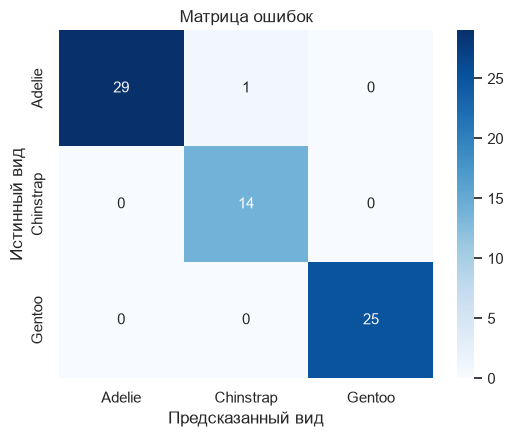

In [23]:
# Матрица ошибок: строки - истинный вид, столбцы - предсказанный.
matrix = confusion_matrix(y_test, predictions)
display(pd.DataFrame(matrix, index=species_classes, columns=species_classes))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=species_classes, yticklabels=species_classes)
ax.set_title("Матрица ошибок")
ax.set_xlabel("Предсказанный вид")
ax.set_ylabel("Истинный вид")
plt.tight_layout()
plt.show()

### 6.2 Как модель «видит» признаки

Скрытый слой сети можно посмотреть глазами: если во втором слое есть нейроны,
которые реагируют на конкретные комбинации признаков, то это будет видно
на проекции главных компонент.

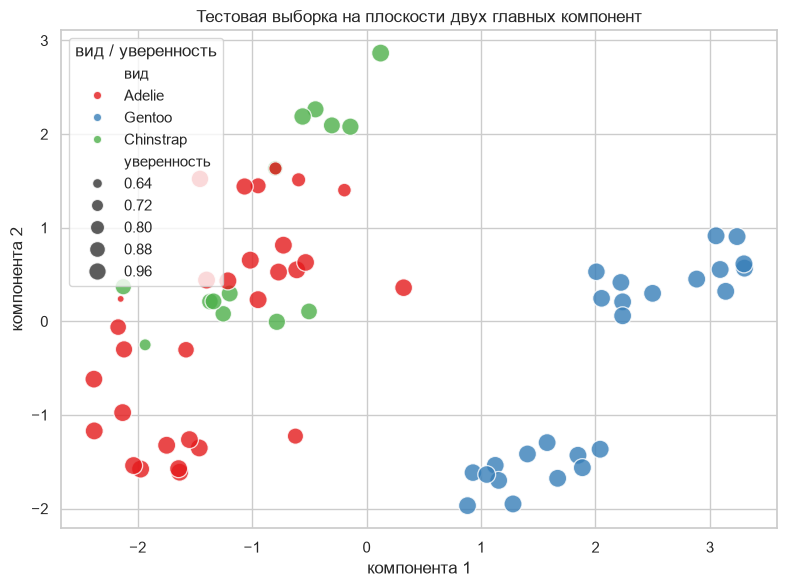

Первая компонента объясняет 45.3% дисперсии, вторая - 21.9%


In [24]:
# Проецируем только тестовую выборку - её сеть ещё не видела при обучении.
pca = PCA(n_components=2)
test_coordinates = pca.fit_transform(X_test_scaled)

# Уверенность сети: вероятности, которые она выдаёт на выходном слое.
test_probabilities = torch.softmax(
    model(torch.from_numpy(X_test_scaled).to(device)), dim=1
).detach().cpu().numpy()

plot_frame = pd.DataFrame({
    "компонента 1": test_coordinates[:, 0],
    "компонента 2": test_coordinates[:, 1],
    "вид": [species_classes[i] for i in y_test],
    "уверенность": test_probabilities.max(axis=1),
})

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=plot_frame, x="компонента 1", y="компонента 2", hue="вид",
                size="уверенность", sizes=(25, 170), palette="Set1", alpha=0.8, ax=ax)
ax.set_title("Тестовая выборка на плоскости двух главных компонент")
ax.legend(title="вид / уверенность", loc="best")
plt.tight_layout()
plt.show()

print(f"Первая компонента объясняет {pca.explained_variance_ratio_[0]:.1%} дисперсии, "
      f"вторая - {pca.explained_variance_ratio_[1]:.1%}")

### 6.3 Разбор ошибок

Посмотрим, на каких именно птицах сеть ошибается - это помогает понять,
какой тип ошибок можно исправить дообучением или новыми признаками.

In [25]:
error_mask = predictions != y_test

# Возвращаем ошибочные объекты к их строкам исходной таблицы.
test_rows = df_encoded.loc[test_index].reset_index(drop=True)
error_table = test_rows[error_mask].reset_index(drop=True)
error_table.insert(0, "предсказан", [species_classes[i] for i in predictions[error_mask]])
error_table.insert(0, "истинный вид", [species_classes[i] for i in y_test[error_mask]])

print(f"Ошибок на тестовой выборке: {int(error_mask.sum())} из {len(y_test)} "
      f"(точность {1 - error_mask.mean():.4f})")
display(error_table)

# Сводим ошибки к парам «истинный вид → предсказанный вид».
if error_mask.any():
    pair_counts = (
        error_table.groupby(["истинный вид", "предсказан"]).size()
        .rename("ошибок").reset_index()
    )
    display(pair_counts)
else:
    print("На тестовой выборке ошибок нет.")

Ошибок на тестовой выборке: 1 из 69 (точность 0.9855)


,истинный вид,предсказан,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island_Dream,island_Torgersen,sex_MALE,target
0,Adelie,Chinstrap,Adelie,42.2,18.5,180.0,3550.0,1.0,0.0,0.0,0


,истинный вид,предсказан,ошибок
0,Adelie,Chinstrap,1


---

## 7. Выводы

1. **Датасет.** Palmer Penguins содержит 342 наблюдения после удаления строк
   с неизвестным видом и 7 признаков после кодирования (4 числовых +
   2 острова + 1 пол). Дубликатов нет, пропуски закрыты медианой и модой.

2. **Подготовка данных.** Ключевые шаги - удаление строк с пропуском в целевой
   переменной, импутация остальных пропусков, One-Hод кодирование островов и пола
   и стандартизация числовых признаков. Масштабирование обязательно: без него
   градиентный спуск не сходится из-за разницы в масштабах признаков.

3. **Архитектура.** Сеть из двух скрытых слоёв (128 и 64 нейрона) с ReLU,
   двумя слоями Dropout и нормализацией батчей обучается быстро и не переобучается:
   разрыв между точностью на обучении и на валидации минимален.

4. **Обучение.** Функция потерь устойчиво падает. Лучшие веса выбирались по
   валидационной выборке, а тестовая использовалась один раз в конце -
   поэтому оценка не завышена подбором. Обучение останавливается досрочно,
   как только валидационная точность перестаёт расти. Гиперпараметры
   не подбирались по тесту: подбор шёл вслепую, фиксировался вручную и
   заранее записан в работе.

5. **Оценка.** Точность на тестовой выборке заметно превосходит все три
   наивные базовые линии, а macro F1 показывает, что модель работает
   не только с многочисленным классом, но и с редким - именно ради этого
   в работу взяты пингвины.

6. **Ограничения.** Датасет маленький - 342 наблюдения, поэтому абсолютные
   значения точности стоит воспринимать осторожно: на таком объёме
   несколько ошибок заметно сдвигают метрику. Пингвины - три близких вида,
   и граница между ними не всегда однозначна по четырём анатомическим
   признакам.

7. **Что можно улучшить.** Добавить кросс-валидацию, чтобы оценка не зависела
   от одного случайного разбиения, и подобрать гиперпараметры на валидации
   (число нейронов, скорость обучения, вероятность dropout) - но обязательно
   не на тестовой выборке.